In [1]:
import pandas as pd

# load the nba team data
df = pd.read_csv("2025-26-team-standings.csv")

# show the first five teams
df.head()

,season,team,team_name,wins,losses,win_pct,games,points_pg,opponent_points_pg,off_rating_est,def_rating_est,net_rating,sos,adjusted_net_rating,pace
0,2025-26,ATL,Atlanta Hawks,46,36,0.5610,82,118.4634,116.0488,113.2451,110.9378,2.3072,-0.0123,2.2949,104.5971
1,2025-26,BKN,Brooklyn Nets,20,62,0.2439,82,105.9268,115.9146,106.0193,116.0389,-10.0196,0.3229,-9.6967,99.9959
2,2025-26,BOS,Boston Celtics,56,26,0.6829,82,114.8537,107.1585,117.2222,109.3338,7.8884,-0.3463,7.5421,97.9912
3,2025-26,CHA,Charlotte Hornets,44,38,0.5366,82,116.0122,111.1829,115.8122,110.9272,4.8850,-0.3635,4.5215,100.2405
4,2025-26,CHI,Chicago Bulls,31,51,0.3780,82,116.3049,121.5122,110.3505,115.3433,-4.9928,0.1208,-4.8720,105.3751


In [2]:
# display all column names
df.columns.tolist()

['season',
 'team',
 'team_name',
 'wins',
 'losses',
 'win_pct',
 'games',
 'points_pg',
 'opponent_points_pg',
 'off_rating_est',
 'def_rating_est',
 'net_rating',
 'sos',
 'adjusted_net_rating',
 'pace']

In [3]:
# select the statistics for clustering
features = ["off_rating_est", "def_rating_est", "pace"]

# create a dataframe with team names and selected statistics
nba_data = df[["team_name"] + features].copy()

# display the first five rows
nba_data.head()

,team_name,off_rating_est,def_rating_est,pace
0,Atlanta Hawks,113.2451,110.9378,104.5971
1,Brooklyn Nets,106.0193,116.0389,99.9959
2,Boston Celtics,117.2222,109.3338,97.9912
3,Charlotte Hornets,115.8122,110.9272,100.2405
4,Chicago Bulls,110.3505,115.3433,105.3751


In [4]:
from sklearn.preprocessing import StandardScaler

# create a scaler
scaler = StandardScaler()

# standardize the three statistics
scaled_data = scaler.fit_transform(nba_data[features])

# display the first five standardized rows
pd.DataFrame(scaled_data, columns=features).head()

,off_rating_est,def_rating_est,pace
0,0.148150,-0.534758,0.995338
1,-2.144732,0.947434,-1.246267
2,1.410158,-1.000822,-2.222913
3,0.962739,-0.537838,-1.127103
4,-0.770361,0.745318,1.374362


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# test different numbers of clusters
k_values = range(2, 9)
scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_data)

    score = silhouette_score(scaled_data, labels)
    scores.append(score)

# display the silhouette scores
results = pd.DataFrame({
    "k": list(k_values),
    "silhouette_score": scores
})

results

,k,silhouette_score
0,2,0.358761
1,3,0.344298
2,4,0.344577
3,5,0.363104
4,6,0.373928
5,7,0.328938
6,8,0.327994


In [6]:
# create six clusters
model = KMeans(n_clusters=6, random_state=42, n_init=10)

# assign each team to a cluster
nba_data["cluster"] = model.fit_predict(scaled_data)

# count how many teams are in each cluster
nba_data["cluster"].value_counts().sort_index()

cluster
0    3
1    3
2    9
3    7
4    7
5    1
Name: count, dtype: int64

In [7]:
# compare cluster sizes for k values from 2 to 5
for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_data)

    print(f"\nk = {k}")
    print(pd.Series(labels).value_counts().sort_index())


k = 2
0    16
1    14
Name: count, dtype: int64

k = 3
0    10
1    12
2     8
Name: count, dtype: int64

k = 4
0     8
1    12
2     8
3     2
Name: count, dtype: int64

k = 5
0     3
1    10
2     7
3     7
4     3
Name: count, dtype: int64


In [8]:
# create the final k-means model with five clusters
final_model = KMeans(n_clusters=5, random_state=42, n_init=10)

# assign each team to a cluster
nba_data["cluster"] = final_model.fit_predict(scaled_data)

# display teams grouped by cluster
nba_data.sort_values(["cluster", "team_name"])

,team_name,off_rating_est,def_rating_est,pace,cluster
1,Brooklyn Nets,106.0193,116.0389,99.9959,0
16,Milwaukee Bucks,110.2854,116.6289,100.2693,0
25,Sacramento Kings,108.6313,118.4281,102.2210,0
2,Boston Celtics,117.2222,109.3338,97.9912,1
3,Charlotte Hornets,115.8122,110.9272,100.2405,1
5,Cleveland Cavaliers,116.1020,112.1569,102.9734,1
7,Denver Nuggets,119.5929,114.5420,102.0924,1
10,Houston Rockets,115.1855,109.9533,100.1185,1
12,LA Clippers,114.3455,113.2416,99.5649,1
13,Los Angeles Lakers,115.3937,113.6945,100.8088,1


In [9]:
# calculate the average statistics for each cluster
cluster_summary = nba_data.groupby("cluster")[features].mean()

# add the number of teams in each cluster
cluster_summary["team_count"] = nba_data.groupby("cluster").size()

# round the results for easier reading
cluster_summary.round(2)

,off_rating_est,def_rating_est,pace,team_count
cluster,,,,
0,108.31,117.03,100.83,3
1,115.52,111.52,100.56,10
2,112.58,111.57,103.94,7
3,109.70,116.54,104.66,7
4,115.73,106.76,102.77,3


In [10]:
# list the teams belonging to each cluster
for cluster in sorted(nba_data["cluster"].unique()):
    teams = nba_data.loc[
        nba_data["cluster"] == cluster, "team_name"
    ].tolist()

    print(f"\nCluster {cluster}:")
    print(", ".join(teams))


Cluster 0:
Brooklyn Nets, Milwaukee Bucks, Sacramento Kings

Cluster 1:
Boston Celtics, Charlotte Hornets, Cleveland Cavaliers, Denver Nuggets, Houston Rockets, LA Clippers, Los Angeles Lakers, New York Knicks, Phoenix Suns, Toronto Raptors

Cluster 2:
Atlanta Hawks, Golden State Warriors, Miami Heat, Minnesota Timberwolves, Orlando Magic, Philadelphia 76ers, Portland Trail Blazers

Cluster 3:
Chicago Bulls, Dallas Mavericks, Indiana Pacers, Memphis Grizzlies, New Orleans Pelicans, Utah Jazz, Washington Wizards

Cluster 4:
Detroit Pistons, Oklahoma City Thunder, San Antonio Spurs


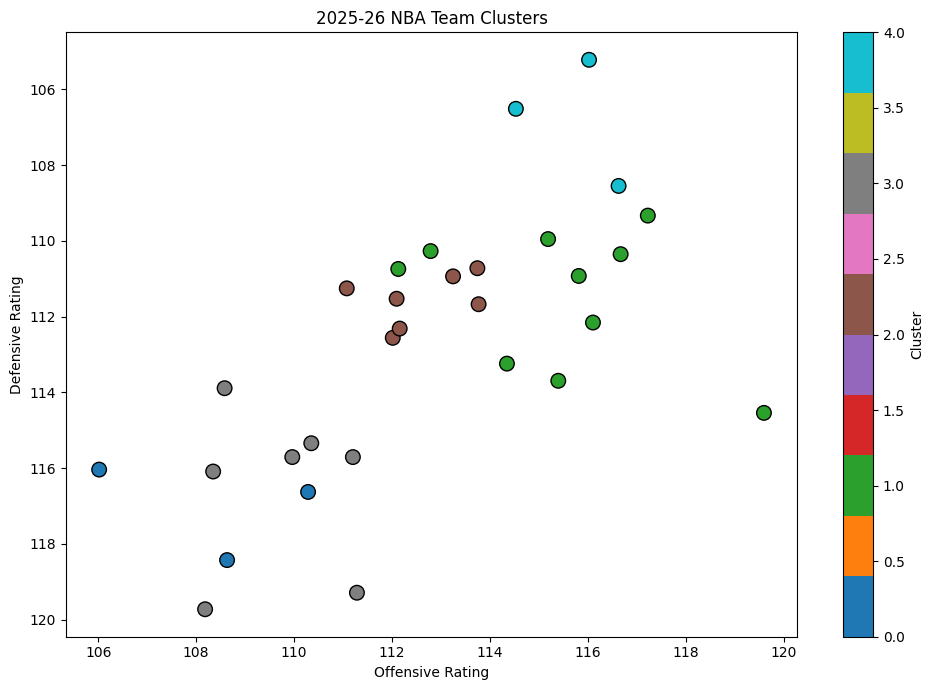

In [11]:
import matplotlib.pyplot as plt

# create a scatterplot of nba team clusters
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    nba_data["off_rating_est"],
    nba_data["def_rating_est"],
    c=nba_data["cluster"],
    cmap="tab10",
    s=110,
    edgecolors="black"
)

# label the axes and chart
plt.xlabel("Offensive Rating")
plt.ylabel("Defensive Rating")
plt.title("2025-26 NBA Team Clusters")

# show cluster labels
plt.colorbar(scatter, label="Cluster")

# lower defensive rating means better defense
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

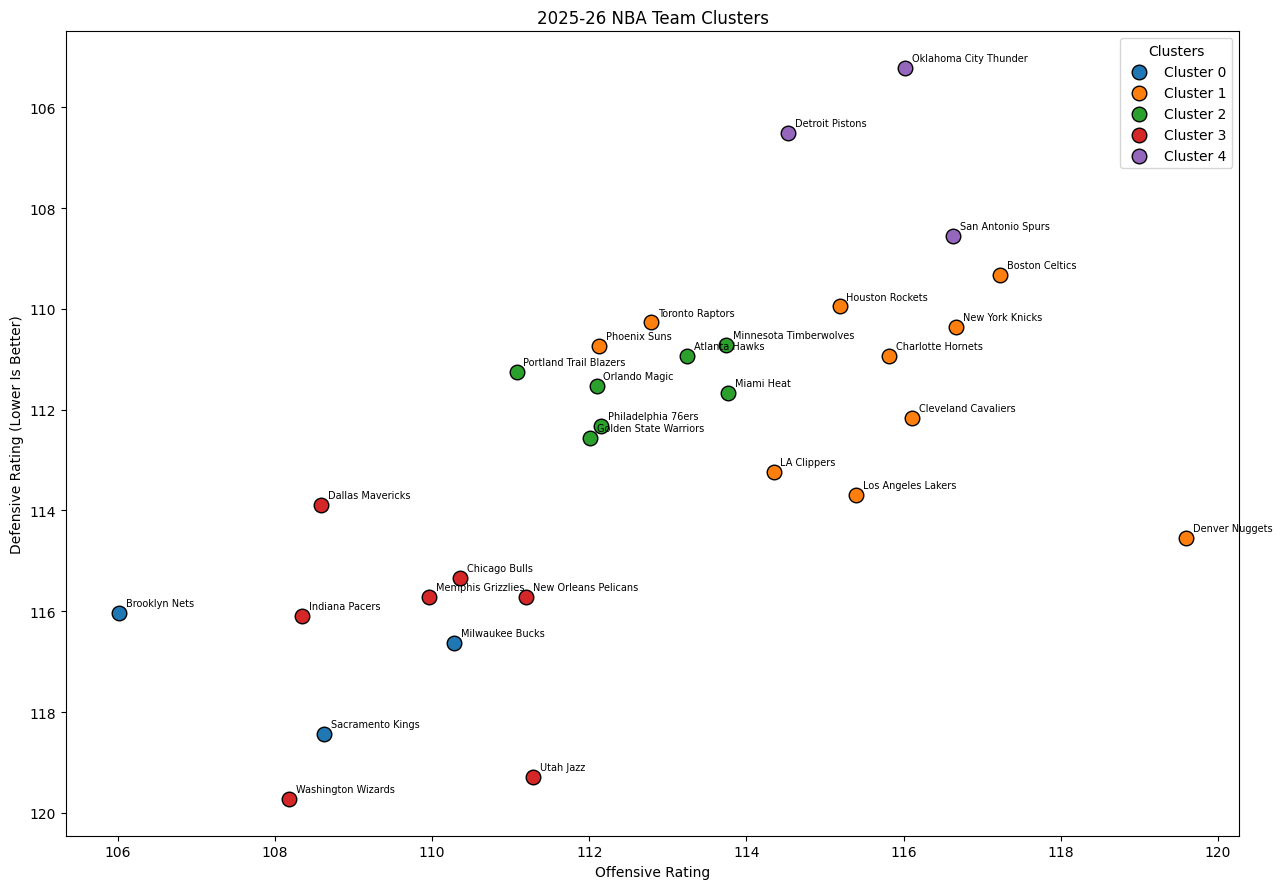

In [12]:
# updating and improving graph 

import matplotlib.pyplot as plt

# create a new figure
fig, ax = plt.subplots(figsize=(13, 9))

# plot each cluster separately
for cluster in sorted(nba_data["cluster"].unique()):
    group = nba_data[nba_data["cluster"] == cluster]

    ax.scatter(
        group["off_rating_est"],
        group["def_rating_est"],
        s=110,
        label=f"Cluster {cluster}",
        edgecolors="black"
    )

# add team names beside the points
for _, team in nba_data.iterrows():
    ax.annotate(
        team["team_name"],
        (team["off_rating_est"], team["def_rating_est"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7
    )

# label the chart
ax.set_title("2025-26 NBA Team Clusters")
ax.set_xlabel("Offensive Rating")
ax.set_ylabel("Defensive Rating (Lower Is Better)")

# show better defensive teams higher on the chart
ax.invert_yaxis()

# add a legend
ax.legend(title="Clusters")

plt.tight_layout()

# save the figure for medium and github
plt.savefig("nba_team_clusters.png", dpi=300, bbox_inches="tight")

plt.show()

In [13]:
# check that all 30 teams were assigned to a cluster
print("total teams:", len(nba_data))

# check for missing values
print("missing values:", nba_data.isnull().sum().sum())

# check the number of clusters
print("number of clusters:", nba_data["cluster"].nunique())

# check the smallest cluster
print("smallest cluster:", nba_data["cluster"].value_counts().min())

# check for duplicate team names
print("duplicate teams:", nba_data["team_name"].duplicated().sum())

# SUNS IN FOUR! 

total teams: 30
missing values: 0
number of clusters: 5
smallest cluster: 3
duplicate teams: 0


In [14]:
# save all teams and their cluster assignments
nba_data.to_csv("nba_cluster_results.csv", index=False)

# save the average statistics for each cluster
cluster_summary.to_csv("nba_cluster_summary.csv")

# confirm that both files were saved
print("cluster results and summary saved successfully")

cluster results and summary saved successfully
